# Fine-tuning Gemma 3 270M as a decision model — `typed-decisions / all`

Runs locally on Apple Silicon (MPS). Trains on the full `all` config (1,200 train cases, 4 workflows) and scores
the 400-case / 2,000-decision `test` split used by the leaderboard, then publishes the model and its scores to the Hub.

**Task.** Each case is one `state` plus 5 typed questions (`noul` yes/no, `choice`, `score` rubric). There are four workflows:

| workflow | questions |
|---|---|
| `agent_trace_observability` | action, needs_review, outcome, risk, urgency |
| `customer_service` | action, category, churn_risk, needs_human, urgency |
| `invoice_processing` | disposition, matches_order, duplicate, discrepancy_severity, urgency |
| `security_incidents` | disposition, true_positive, credential_compromise, severity, urgency |

Question names repeat across workflows (`urgency`, `disposition`, `action`), so results are keyed by `workflow/question`.

Gold answers are **probability distributions** (mean of 3 teacher samples), and the benchmark scores
accuracy *and* calibration (KL, Brier, ECE).

**Approach.** Each (case, question) pair becomes one prompt that lists the options as letters `A`, `B`, `C`, …
We read Gemma's next-token logits restricted to those letter tokens, softmax them into a distribution,
and fine-tune the full model with a **soft cross-entropy against the gold distribution**. This gives a proper
probabilistic classifier (no text generation or JSON parsing) and keeps the model's LM head as the decision head.

## 1. Setup

In [65]:
# Dependencies are in pyproject.toml / uv.lock: run `uv sync` in the repo and use .venv as the kernel.
# Without uv, uncomment:
# %pip install -q -r requirements.txt

In [66]:
import json, math, random, time, copy, os, gc
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, get_cosine_schedule_with_warmup
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import optuna

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
AMP = DEVICE == "cuda" and torch.cuda.is_bf16_supported()   # bf16 autocast on GPUs that support it (fp32 weights)
print("device:", DEVICE, "| bf16 autocast:", AMP, "| torch", torch.__version__)

def empty_cache():
    gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()
    elif DEVICE == "mps": torch.mps.empty_cache()

device: cuda | bf16 autocast: True | torch 2.14.1+cu130


### Hyperparameters
`google/gemma-3-270m-it` is gated: accept the license on its Hugging Face page and run `uv run hf auth login` once.
Full fine-tuning in fp32 needs ~5 GB of memory (weights + AdamW states): fine on an M3 Pro or any recent GPU.
The values below are the defaults; the optional Optuna search in section 5 can replace them (`USE_BEST_HPARAMS`).

In [67]:
MODEL_ID   = "google/gemma-3-270m-it"
CONFIG     = "all"    # all 4 workflows: 1,200 train / 400 test cases
MAX_LEN    = 1024     # longest prompt is ~800 tokens
BATCH_SIZE = 8
GRAD_ACCUM = 2        # effective batch 16
EPOCHS     = 12        # ~5,400 training decisions per epoch
LR         = 3e-5
WEIGHT_DECAY = 0.01
WARMUP_FRAC  = 0.1
VAL_FRAC     = 0.1    # held-out part of train (by case) for model selection
OUT_DIR    = "gemma3-270m-typed-decisions"

# optional hyperparameter search (section 5)
RUN_HPO          = True  # run the Optuna search (meant for a CUDA GPU)
HPO_BUDGET_MIN   = 60    # hard wall-clock cap for the whole search, in minutes (2 h minus a safety margin)
HPO_TRAIN_FRAC   = 0.5    # fraction of the training cases each trial trains on (faster trials, more of them)
USE_BEST_HPARAMS = True   # final training uses hpo/best_hparams.json if it exists, else the defaults above
HPO_DIR          = "hpo"

# run tracking (section 6b): every run gets runs/<timestamp>_<model>_<config>[_<tag>]/ with its summary
RUNS_DIR = "runs"
RUN_TAG  = ""             # optional short label for this run, e.g. "lr-sweep" or "hpo-best"

## 2. Data

In [68]:
train_raw = load_dataset("LocalLLaMA/typed-decisions", CONFIG, split="train")
test_raw  = load_dataset("LocalLLaMA/typed-decisions", CONFIG, split="test")
print(train_raw, test_raw, sep="\n")

row = train_raw[0]
state, questions, gold = (json.loads(row[k]) for k in ("state", "questions", "gold"))
qname = next(iter(questions))
print(row["workflow"]); print(json.dumps(state, indent=1)[:1200])
print(json.dumps(questions[qname], indent=1))
print(json.dumps(gold[qname], indent=1))
print(pd.Series(train_raw["workflow"]).value_counts())

Dataset({
    features: ['id', 'workflow', 'split', 'state', 'questions', 'gold', 'factors', 'label_agreement', 'n_questions'],
    num_rows: 1200
})
Dataset({
    features: ['id', 'workflow', 'split', 'state', 'questions', 'gold', 'factors', 'label_agreement', 'n_questions'],
    num_rows: 400
})
agent_trace_observability
{
 "agent": {
  "autonomy": "checkpointed",
  "model": "internal-agent-v4"
 },
 "constraints": [
  "Do not touch customer data outside the named accounts"
 ],
 "task": "Delete personal data for the accounts in the erasure queue.",
 "trace_summary": {
  "constraint_violations": 0,
  "duration_s": 128.5,
  "irreversible_actions": 0,
  "steps": 7,
  "tool_errors": 1
 }
}
{
 "criteria": {
  "continue": "Let the agent proceed without interruption.",
  "human_review": "Queue this trace for a human to review.",
  "observe": "Keep running, but flag the trace for later sampling.",
  "stop": "Halt the agent now."
 },
 "instructions": "What should the observability system do wi

### Turning questions into option lists
* `choice` → its `criteria` dict keys (label → description)
* `noul` → `true` / `false` (with descriptions when given; some, e.g. `duplicate`, have none, so we use a generic one)
* `score` → levels `0..N-1`, each with its rubric text

The gold `probabilities` dict is keyed by the same labels, so we can line them up as a vector.

In [69]:
LETTERS = "ABCDEFGHIJ"

def question_options(q):
    """Return [(label, description), ...] in a fixed order."""
    t, crit = q["type"], q.get("criteria")
    if t == "choice":
        return list(crit.items())
    if t == "noul":
        crit = crit or {}
        return [("true",  crit.get("true",  "The statement is true.")),
                ("false", crit.get("false", "The statement is false."))]
    if t == "score":
        return [(str(i), d) for i, d in enumerate(crit)]
    raise ValueError(t)

SYSTEM = ("You are a precise decision model. Read the case, then answer the question "
          "with the single letter of the best option.")

def build_prompt(state, qname, q):
    opts = question_options(q)
    kind = {"choice": "Choose one option.",
            "noul":   "Is the statement true or false?",
            "score":  "Pick the level on the rubric."}[q["type"]]
    lines = [f"{LETTERS[i]}. {lab}: {desc}" for i, (lab, desc) in enumerate(opts)]
    return (f"{SYSTEM}\n\n### Case\n{json.dumps(state, separators=(',', ':'))}\n\n"
            f"### Question ({qname})\n{q['instructions']}\n{kind}\n\n### Options\n" + "\n".join(lines)
            + "\n\nAnswer with one letter.")

def expand(ds, desc="expand"):
    """One example per (case, question)."""
    out = []
    for r in tqdm(ds, desc=desc, unit="case"):
        state, qs, gold = (json.loads(r[k]) for k in ("state", "questions", "gold"))
        for qname, q in qs.items():
            opts = question_options(q)
            labels = [lab for lab, _ in opts]
            p = np.array([gold[qname]["probabilities"].get(l, 0.0) for l in labels], dtype=np.float32)
            p = p / p.sum()
            out.append(dict(case_id=r["id"], workflow=r["workflow"], qname=qname,
                            task=f"{r['workflow']}/{qname}", qtype=q["type"], labels=labels,
                            prompt=build_prompt(state, qname, q), gold_p=p,
                            gold_label=gold[qname]["label"]))
    return out

train_all = expand(train_raw, desc="build train prompts")
test_ex   = expand(test_raw,  desc="build test prompts")

# split train by case so no case leaks between train/val
case_ids = sorted({e["case_id"] for e in train_all})
random.Random(SEED).shuffle(case_ids)
val_cases = set(case_ids[:int(len(case_ids) * VAL_FRAC)])
train_ex = [e for e in train_all if e["case_id"] not in val_cases]
val_ex   = [e for e in train_all if e["case_id"] in val_cases]
print(f"train {len(train_ex)} | val {len(val_ex)} | test {len(test_ex)} examples")
print(train_ex[0]["prompt"])

build train prompts:   0%|          | 0/1200 [00:00<?, ?case/s]

build test prompts:   0%|          | 0/400 [00:00<?, ?case/s]

train 5400 | val 600 | test 2000 examples
You are a precise decision model. Read the case, then answer the question with the single letter of the best option.

### Case
{"agent":{"autonomy":"checkpointed","model":"internal-agent-v4"},"constraints":["Do not touch customer data outside the named accounts"],"task":"Delete personal data for the accounts in the erasure queue.","trace_summary":{"constraint_violations":0,"duration_s":128.5,"irreversible_actions":0,"steps":7,"tool_errors":1}}

### Question (action)
What should the observability system do with this trace?
Choose one option.

### Options
A. continue: Let the agent proceed without interruption.
B. human_review: Queue this trace for a human to review.
C. observe: Keep running, but flag the trace for later sampling.
D. stop: Halt the agent now.

Answer with one letter.


Label distribution of the gold argmax on train (useful to see class imbalance):

In [70]:
pd.DataFrame(train_all).groupby("task")["gold_label"].value_counts(normalize=True).unstack().round(3)

gold_label,0,1,2,3,4,account,answer_directly,approve,billing,close_benign,...,monitor,observe,partial,refund,reject,request_information,stop,success,technical,true
task,,,,,,,,,,,,,,,,,,,,,
agent_trace_observability/action,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.407,NaN,NaN,NaN,NaN,0.01,NaN,NaN,NaN
agent_trace_observability/needs_review,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.487
agent_trace_observability/outcome,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.47,NaN,NaN,NaN,NaN,0.273,NaN,NaN
agent_trace_observability/risk,0.223,0.353,0.217,0.207,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
agent_trace_observability/urgency,0.233,0.507,0.087,0.173,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_service/action,NaN,NaN,NaN,NaN,NaN,NaN,0.217,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.197,NaN,NaN,NaN,NaN
customer_service/category,NaN,NaN,NaN,NaN,NaN,0.257,NaN,NaN,0.227,NaN,...,NaN,NaN,NaN,0.09,NaN,NaN,NaN,NaN,0.227,NaN
customer_service/churn_risk,0.050,0.247,0.487,0.217,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_service/needs_human,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.670


## 3. Model & tokenisation

In [71]:
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float32,
                                             attn_implementation="eager").to(DEVICE)
print(f"{sum(p.numel() for p in model.parameters())/1e6:.1f}M params")
base_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}   # to restart from

# token id for each option letter (as the first token of the model's reply)
LETTER_IDS = []
for L in LETTERS:
    ids = tok.encode(L, add_special_tokens=False)
    assert len(ids) == 1, (L, ids)
    LETTER_IDS.append(ids[0])
print(dict(zip(LETTERS[:5], LETTER_IDS[:5])))

def to_chat(prompt):
    return tok.apply_chat_template([{"role": "user", "content": prompt}],
                                   tokenize=False, add_generation_prompt=True)

for name, split in (("train", train_ex), ("val", val_ex), ("test", test_ex)):
    for e in tqdm(split, desc=f"tokenize {name}", unit="ex"):
        e["input_ids"] = tok(to_chat(e["prompt"]), add_special_tokens=False)["input_ids"][:MAX_LEN]

lens = [len(e["input_ids"]) for e in train_ex]
print("prompt tokens: mean", int(np.mean(lens)), "max", max(lens))

Loading weights:   0%|          | 0/236 [00:00<?, ?it/s]

268.1M params
{'A': 236776, 'B': 236799, 'C': 236780, 'D': 236796, 'E': 236788}


tokenize train:   0%|          | 0/5400 [00:00<?, ?ex/s]

tokenize val:   0%|          | 0/600 [00:00<?, ?ex/s]

tokenize test:   0%|          | 0/2000 [00:00<?, ?ex/s]

prompt tokens: mean 338 max 747


Batches are right-padded; we gather the logits at the **last real token** of each sequence
(the position after `<start_of_turn>model\n`) and keep only the option-letter columns.

In [72]:
def collate(batch):
    L = max(len(e["input_ids"]) for e in batch)
    pad = tok.pad_token_id
    ids  = torch.full((len(batch), L), pad, dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        ids[i, :n] = torch.tensor(e["input_ids"]); mask[i, :n] = 1
    K = max(len(e["labels"]) for e in batch)
    target = torch.zeros((len(batch), K))
    opt_mask = torch.zeros((len(batch), K), dtype=torch.bool)
    for i, e in enumerate(batch):
        k = len(e["labels"])
        target[i, :k] = torch.from_numpy(e["gold_p"]); opt_mask[i, :k] = True
    return ids, mask, target, opt_mask

LETTER_IDS_T = torch.tensor(LETTER_IDS, device=DEVICE)   # sliced to the batch's option count (max 5 in `all`)

def option_logits(model, ids, mask, opt_mask):
    out = model(input_ids=ids, attention_mask=mask)
    last = mask.sum(1) - 1
    logits = out.logits[torch.arange(ids.size(0), device=ids.device), last]   # (B, V)
    logits = logits[:, LETTER_IDS_T[:opt_mask.size(1)]]                        # (B, K)
    return logits.masked_fill(~opt_mask, float("-inf"))

def soft_ce(logits, target):
    logp = F.log_softmax(logits.float(), dim=-1).masked_fill(target == 0, 0.0)
    return -(target * logp).sum(-1).mean()

## 4. Evaluation helpers
Metrics per decision, then averaged:
* **Accuracy** – argmax of prediction equals the gold `label`
* **KL(gold ‖ pred)** – how far the predicted distribution is from the gold one
* **Brier** – Σₖ (pₖ − gₖ)² against the soft gold distribution
* **ECE** – 10-bin expected calibration error of max-probability vs. correctness

In [73]:
@torch.no_grad()
def predict(model, examples, bs=16, desc="predict"):
    model.eval()
    preds = []
    for i in tqdm(range(0, len(examples), bs), desc=desc, unit="batch", leave=False,
                  disable=len(examples) <= bs):
        batch = examples[i:i + bs]
        ids, mask, _, opt_mask = collate(batch)
        with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=AMP):
            lg = option_logits(model, ids.to(DEVICE), mask.to(DEVICE), opt_mask.to(DEVICE))
        P = F.softmax(lg.float(), -1).cpu().numpy()
        for e, p in zip(batch, P):
            preds.append(p[:len(e["labels"])])
    return preds

def ece(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf), np.asarray(correct, dtype=float)
    bins = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    return sum(np.abs(correct[bins == b].mean() - conf[bins == b].mean()) * (bins == b).mean()
               for b in range(n_bins) if (bins == b).any())

def score(examples, preds, by="task"):
    """Metrics grouped by `by` ("task", "workflow" or "qtype"), plus an OVERALL row."""
    rows = []
    for e, p in tqdm(zip(examples, preds), total=len(examples), desc="score", unit="ex", leave=False):
        g = e["gold_p"]; pc = np.clip(p, 1e-8, 1)
        rows.append(dict(task=e["task"], workflow=e["workflow"], qtype=e["qtype"],
                         correct=e["labels"][int(p.argmax())] == e["gold_label"],
                         kl=float(np.sum(np.where(g > 0, g * (np.log(np.clip(g, 1e-8, 1)) - np.log(pc)), 0))),
                         brier=float(np.sum((p - g) ** 2)), conf=float(p.max())))
    df = pd.DataFrame(rows)
    summary = lambda d: pd.Series(dict(accuracy=d.correct.mean(), kl=d.kl.mean(), brier=d.brier.mean(),
                                       ece=ece(d.conf, d.correct), n=len(d)))
    per_q = df.groupby(by).apply(summary, include_groups=False)
    per_q.loc["OVERALL"] = summary(df)
    return per_q.round(4)

### Reference baselines on the test split
*Uniform* (equal probability on every option) and *Prior* (train label frequencies, ignoring the input).

In [74]:
uniform_preds = [np.full(len(e["labels"]), 1 / len(e["labels"])) for e in test_ex]

prior = {}
for e in tqdm(train_all, desc="label priors", unit="ex"):
    prior.setdefault(e["task"], []).append(e["gold_p"])
prior = {q: np.mean(v, 0) for q, v in prior.items()}
prior_preds = [prior[e["task"]] for e in test_ex]

print("Uniform"); display(score(test_ex, uniform_preds).loc[["OVERALL"]])
print("Prior");   display(score(test_ex, prior_preds).loc[["OVERALL"]])

label priors:   0%|          | 0/6000 [00:00<?, ?ex/s]

Uniform


score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece,n
task,,,,,
OVERALL,0.274,0.4445,0.2382,0.0485,2000.0


Prior


score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece,n
task,,,,,
OVERALL,0.4785,0.3274,0.1811,0.0336,2000.0


### Zero-shot Gemma 3 270M (before fine-tuning)

In [75]:
t0 = time.time()
zs_preds = predict(model, test_ex, desc="zero-shot test")
print(f"{time.time() - t0:.1f}s for {len(test_ex)} decisions")
zero_shot = score(test_ex, zs_preds)
zero_shot

zero-shot test:   0%|          | 0/125 [00:00<?, ?batch/s]

28.2s for 2000 decisions


score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece,n
task,,,,,
agent_trace_observability/action,0.240,0.3399,0.1705,0.1716,100.0
agent_trace_observability/needs_review,0.490,0.2158,0.1950,0.1058,100.0
agent_trace_observability/outcome,0.180,1.3829,0.5515,0.3372,100.0
agent_trace_observability/risk,0.340,1.2025,0.3869,0.3402,100.0
agent_trace_observability/urgency,0.370,0.8590,0.2867,0.2813,100.0
customer_service/action,0.210,1.1279,0.4211,0.2532,100.0
customer_service/category,0.390,1.7603,0.7089,0.2853,100.0
customer_service/churn_risk,0.090,1.8957,0.5145,0.4031,100.0
customer_service/needs_human,0.620,0.1303,0.1170,0.0354,100.0


## 5. Fine-tuning
Plain PyTorch loop: AdamW, cosine schedule with warmup, gradient accumulation, and selection of the epoch with the lowest validation KL (calibration is what the benchmark rewards). The loop is a function so the hyperparameter search and the final run share it.

In [76]:
def train_model(model, train_ex, val_ex, lr, weight_decay, warmup_frac, grad_accum, epochs,
                trial=None, deadline=None, desc="epochs"):
    """Fine-tune `model` in place. Returns (history, best_state) where best_state is the epoch with the lowest
    val KL (None during a search). With an Optuna `trial`: reports val KL each epoch for pruning, and stops
    as soon as time.time() passes `deadline`."""
    optim = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    total_steps = math.ceil(len(train_ex) / BATCH_SIZE / grad_accum) * epochs
    sched = get_cosine_schedule_with_warmup(optim, int(warmup_frac * total_steps), total_steps)
    rng = random.Random(SEED)
    best_kl, best_state, history = float("inf"), None, []
    for epoch in tqdm(range(1, epochs + 1), desc=desc, unit="epoch", leave=trial is None):
        model.train()
        order = list(range(len(train_ex)))
        rng.shuffle(order)
        t0, run_loss, n = time.time(), 0.0, 0
        bar = tqdm(enumerate(range(0, len(order), BATCH_SIZE)), total=math.ceil(len(order) / BATCH_SIZE),
                   desc=f"epoch {epoch}/{epochs}", unit="batch", leave=False)
        for step, i in bar:
            ids, mask, target, opt_mask = collate([train_ex[j] for j in order[i:i + BATCH_SIZE]])
            with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=AMP):
                lg = option_logits(model, ids.to(DEVICE), mask.to(DEVICE), opt_mask.to(DEVICE))
            loss = soft_ce(lg, target.to(DEVICE))
            (loss / grad_accum).backward()
            run_loss += loss.item(); n += 1
            if (step + 1) % grad_accum == 0 or i + BATCH_SIZE >= len(order):
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optim.step(); sched.step(); optim.zero_grad(set_to_none=True)
            bar.set_postfix(loss=f"{run_loss / n:.4f}", lr=f"{sched.get_last_lr()[0]:.2e}")
            if deadline is not None and time.time() > deadline:
                raise optuna.TrialPruned("time budget reached")
        val = score(val_ex, predict(model, val_ex, desc=f"val epoch {epoch}")).loc["OVERALL"]
        history.append(dict(epoch=epoch, train_loss=run_loss / n, val_acc=val.accuracy, val_kl=val.kl,
                            val_brier=val.brier, minutes=(time.time() - t0) / 60))
        tqdm.write(f"{desc} " + str({k: round(float(v), 4) for k, v in history[-1].items()}))
        if val.kl < best_kl:
            best_kl = val.kl
            if trial is None:
                best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}
        if trial is not None:
            trial.report(val.kl, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned(f"pruned after epoch {epoch}")
        empty_cache()
    return history, best_state

### 5a. Optional: hyperparameter search with Optuna
Set `RUN_HPO = True` to run it (skipped otherwise). Meant for a CUDA GPU; on Apple Silicon the same budget fits
only a handful of trials.

* **Objective:** lowest validation KL over a trial's epochs (same criterion as the final run's epoch selection).
* **Search space:** learning rate, weight decay, warmup fraction, gradient accumulation (effective batch), epochs.
* **Speed:** each trial trains on `HPO_TRAIN_FRAC` of the training cases (split by case) and is scored on the full
  validation set; a median pruner stops trials whose val KL after an epoch is worse than the median of earlier trials.
* **Time cap:** `HPO_BUDGET_MIN` is a hard wall-clock limit for the whole search. Optuna's own `timeout` only stops
  *starting* new trials, so the training loop also checks the deadline every batch and aborts the running trial.
* **Resumable:** trials are stored in `hpo/optuna.db`; re-running continues the same study with a fresh budget.
  The best parameters go to `hpo/best_hparams.json`, which the final training picks up.

In [77]:
BEST_HP_PATH = f"{HPO_DIR}/best_hparams.json"
hpo_minutes = None

if RUN_HPO:
    if DEVICE != "cuda":
        print(f"warning: running the search on {DEVICE}; expect few trials within {HPO_BUDGET_MIN} min")
    os.makedirs(HPO_DIR, exist_ok=True)
    hpo_cases = set(random.Random(SEED).sample(sorted({e["case_id"] for e in train_ex}),
                                               int(len({e["case_id"] for e in train_ex}) * HPO_TRAIN_FRAC)))
    hpo_train = [e for e in train_ex if e["case_id"] in hpo_cases]
    print(f"each trial trains on {len(hpo_cases)} cases ({len(hpo_train)} decisions), validates on {len(val_ex)}")

    deadline = time.time() + HPO_BUDGET_MIN * 60

    def objective(trial):
        hp = dict(lr=trial.suggest_float("lr", 5e-6, 2e-4, log=True),
                  weight_decay=trial.suggest_float("weight_decay", 0.0, 0.1),
                  warmup_frac=trial.suggest_float("warmup_frac", 0.0, 0.2),
                  grad_accum=trial.suggest_categorical("grad_accum", [1, 2, 4]),
                  epochs=trial.suggest_int("epochs", 2, 5))
        model.load_state_dict(base_state)            # every trial starts from the pretrained weights
        try:
            history, _ = train_model(model, hpo_train, val_ex, **hp, trial=trial, deadline=deadline,
                                     desc=f"trial {trial.number}")
        finally:
            model.zero_grad(set_to_none=True)
            empty_cache()
        best = min(history, key=lambda h: h["val_kl"])
        trial.set_user_attr("best_epoch", best["epoch"])
        trial.set_user_attr("val_acc", round(best["val_acc"], 4))
        return best["val_kl"]

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(study_name=f"gemma3-270m-{CONFIG}", direction="minimize",
                                storage=f"sqlite:///{HPO_DIR}/optuna.db", load_if_exists=True,
                                sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=1))
    if not any(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials):
        # start from the defaults so the search can only improve on them
        study.enqueue_trial(dict(lr=LR, weight_decay=WEIGHT_DECAY, warmup_frac=WARMUP_FRAC,
                                 grad_accum=GRAD_ACCUM, epochs=min(max(EPOCHS, 2), 5)))
    t_start = time.time()
    study.optimize(objective, timeout=HPO_BUDGET_MIN * 60, gc_after_trial=True, show_progress_bar=True,
                   callbacks=[lambda st, tr: st.stop() if time.time() > deadline else None])
    model.load_state_dict(base_state)                # leave the model untouched for the final training

    states = pd.Series([t.state.name for t in study.trials]).value_counts().to_dict()
    hpo_minutes = (time.time() - t_start) / 60
    print(f"search took {hpo_minutes:.1f} min | trials: {states}")
    print(f"best val KL {study.best_value:.4f} | {study.best_params} | {study.best_trial.user_attrs}")
    json.dump({"params": study.best_params, "val_kl": study.best_value, **study.best_trial.user_attrs,
               "hpo_train_frac": HPO_TRAIN_FRAC, "n_trials": len(study.trials), "device": DEVICE},
              open(BEST_HP_PATH, "w"), indent=1)
    print("saved", BEST_HP_PATH)
    display(study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state", "duration"))
            .sort_values("value").head(10))
else:
    print("RUN_HPO is False; skipping the search",
          f"({BEST_HP_PATH} exists from an earlier run)" if os.path.exists(BEST_HP_PATH) else "")

each trial trains on 540 cases (2700 decisions), validates on 600


   0%|          | 00:00/1:00:00

trial 9:   0%|          | 0/2 [00:00<?, ?epoch/s]

epoch 1/2:   0%|          | 0/338 [00:00<?, ?batch/s]

val epoch 1:   0%|          | 0/38 [00:00<?, ?batch/s]

...

trial 23 {'epoch': 1.0, 'train_loss': 1.2376, 'val_acc': 0.45, 'val_kl': 0.4324, 'val_brier': 0.24, 'minutes': 2.7433}


trial 24:   0%|          | 0/3 [00:00<?, ?epoch/s]

epoch 1/3:   0%|          | 0/338 [00:00<?, ?batch/s]

search took 60.0 min | trials: {'PRUNED': 18, 'COMPLETE': 5, 'RUNNING': 1, 'FAIL': 1}
best val KL 0.2701 | {'lr': 3e-05, 'weight_decay': 0.01, 'warmup_frac': 0.1, 'grad_accum': 2, 'epochs': 4} | {'best_epoch': 4, 'val_acc': 0.64}
saved hpo/best_hparams.json


,number,value,params_epochs,params_grad_accum,params_lr,params_warmup_frac,params_weight_decay,user_attrs_best_epoch,user_attrs_val_acc,state,duration
1,1,0.2701,4,2,0.000030,0.100000,0.010000,4.0,0.6400,COMPLETE,0 days 00:11:25.459161
2,2,0.2783,2,1,0.000020,0.146399,0.095071,2.0,0.6283,COMPLETE,0 days 00:06:23.547608
4,4,0.2783,2,1,0.000020,0.146399,0.095071,2.0,0.6283,COMPLETE,0 days 00:06:25.353136
9,9,0.2783,2,1,0.000020,0.146399,0.095071,2.0,0.6283,COMPLETE,0 days 00:06:04.194343
13,13,0.3092,5,1,0.000024,0.086077,0.043861,NaN,NaN,PRUNED,0 days 00:06:12.616166
18,18,0.3457,2,1,0.000010,0.080274,0.074116,NaN,NaN,PRUNED,0 days 00:06:05.244202
19,19,0.3527,2,1,0.000010,0.192198,0.089869,NaN,NaN,PRUNED,0 days 00:06:04.938782
20,20,0.3581,2,1,0.000010,0.132638,0.042694,NaN,NaN,PRUNED,0 days 00:06:05.233217
5,5,0.3713,2,2,0.000122,0.141615,0.060112,2.0,0.5050,COMPLETE,0 days 00:05:43.634691
7,7,0.4098,4,2,0.000008,0.073272,0.029214,NaN,NaN,PRUNED,0 days 00:04:43.514741


weight_decay    0.499
warmup_frac     0.290
lr              0.164
epochs          0.043
grad_accum      0.004
Name: importance, dtype: float64

/tmp/ipykernel_8693/994804223.py:6: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study); plt.show()


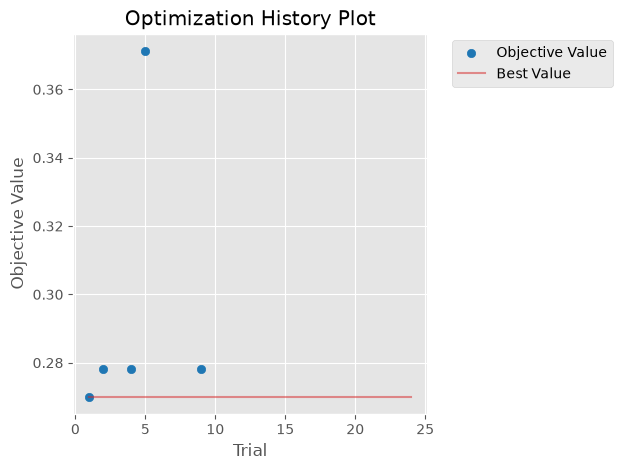

In [78]:
if RUN_HPO and len(study.trials) > 1:
    try:   # which hyperparameters mattered (needs a few completed trials)
        display(pd.Series(optuna.importance.get_param_importances(study), name="importance").round(3))
    except Exception as err:
        print("importance not available:", err)
    optuna.visualization.matplotlib.plot_optimization_history(study); plt.show()

### 5b. Final training
Uses the best search result when `USE_BEST_HPARAMS` is on and `hpo/best_hparams.json` exists (from this or an
earlier run, e.g. a search on a GPU machine), otherwise the defaults from the hyperparameter cell. Training starts from
the pretrained weights on the full training set.

In [102]:
N_EPOCHS = 12
HPARAMS = dict(lr=LR, weight_decay=WEIGHT_DECAY, warmup_frac=WARMUP_FRAC, grad_accum=GRAD_ACCUM, epochs=N_EPOCHS)
HPARAMS_SOURCE = "defaults"
if USE_BEST_HPARAMS and os.path.exists(BEST_HP_PATH):
    HPARAMS.update(json.load(open(BEST_HP_PATH))["params"])
    HPARAMS_SOURCE = f"Optuna search ({BEST_HP_PATH})"
LR, WEIGHT_DECAY, WARMUP_FRAC, GRAD_ACCUM, EPOCHS = (HPARAMS[k] for k in
                                                     ("lr", "weight_decay", "warmup_frac", "grad_accum", "epochs"))
print("hyperparameters from", HPARAMS_SOURCE, "->", HPARAMS)

model.load_state_dict(base_state)
t_train = time.time()
history, best_state = train_model(model, train_ex, val_ex, **HPARAMS)
train_minutes = (time.time() - t_train) / 60
empty_cache()
pd.DataFrame(history).round(4)

hyperparameters from Optuna search (hpo/best_hparams.json) -> {'lr': 3e-05, 'weight_decay': 0.01, 'warmup_frac': 0.1, 'grad_accum': 2, 'epochs': 12}


epochs:   0%|          | 0/12 [00:00<?, ?epoch/s]

epoch 1/12:   0%|          | 0/675 [00:00<?, ?batch/s]

val epoch 1:   0%|          | 0/38 [00:00<?, ?batch/s]

score:   0%|          | 0/600 [00:00<?, ?ex/s]

...

epoch 12/12:   0%|          | 0/675 [00:00<?, ?batch/s]

val epoch 12:   0%|          | 0/38 [00:00<?, ?batch/s]

score:   0%|          | 0/600 [00:00<?, ?ex/s]

epochs {'epoch': 12.0, 'train_loss': 0.7864, 'val_acc': 0.7467, 'val_kl': 0.1409, 'val_brier': 0.0771, 'minutes': 5.435}


,epoch,train_loss,val_acc,val_kl,val_brier,minutes
0,1,1.1898,0.4967,0.3800,0.2151,5.7836
1,2,1.0335,0.6400,0.2627,0.1483,5.8714
2,3,0.9546,0.6800,0.2265,0.1272,5.4460
3,4,0.9059,0.7233,0.1861,0.1059,5.4430
4,5,0.8848,0.7217,0.1868,0.1089,5.4285
5,6,0.8704,0.7283,0.1707,0.1024,5.4155
6,7,0.8565,0.7117,0.1891,0.1114,5.4540
7,8,0.8445,0.7300,0.1723,0.1025,5.4226
8,9,0.8344,0.7417,0.1499,0.0868,5.4431
9,10,0.8078,0.7433,0.1540,0.0855,5.4260


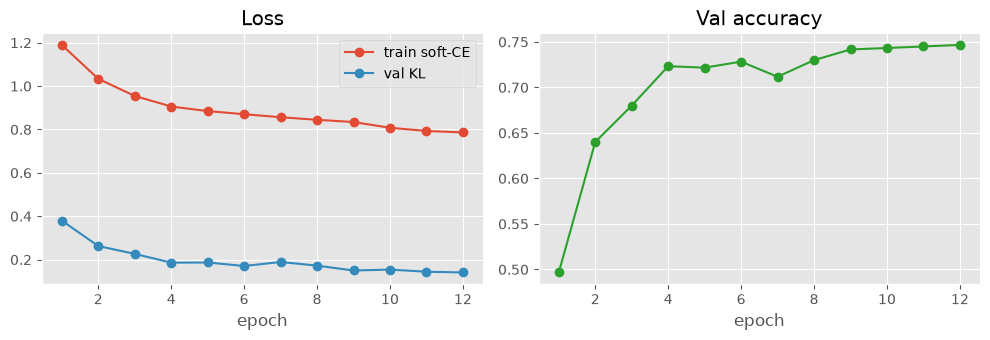

In [103]:
h = pd.DataFrame(history)
curves_fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h.epoch, h.train_loss, marker="o", label="train soft-CE")
ax[0].plot(h.epoch, h.val_kl, marker="o", label="val KL")
ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(h.epoch, h.val_acc, marker="o", color="tab:green")
ax[1].set_xlabel("epoch"); ax[1].set_title("Val accuracy")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6. Evaluate on the test split

In [104]:
model.load_state_dict(best_state)
t0 = time.time()
ft_preds = predict(model, test_ex, desc="fine-tuned test")
ms_per_case = (time.time() - t0) / len(test_raw) * 1000
print(f"{ms_per_case:.0f} ms per case (5 decisions) on {DEVICE}")
fine_tuned = score(test_ex, ft_preds)
display(score(test_ex, ft_preds, by="qtype"))
display(score(test_ex, ft_preds, by="workflow"))
fine_tuned

fine-tuned test:   0%|          | 0/125 [00:00<?, ?batch/s]

68 ms per case (5 decisions) on cuda


score:   0%|          | 0/2000 [00:00<?, ?ex/s]

score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece,n
qtype,,,,,
choice,0.7317,0.1671,0.0853,0.1122,600.0
noul,0.8217,0.0887,0.0623,0.0660,600.0
score,0.7388,0.1380,0.0683,0.1583,800.0
OVERALL,0.7615,0.1319,0.0716,0.1146,2000.0


score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece,n
workflow,,,,,
agent_trace_observability,0.7400,0.0953,0.0568,0.1626,500.0
customer_service,0.7720,0.1335,0.0703,0.1137,500.0
invoice_processing,0.7840,0.2175,0.1146,0.0875,500.0
security_incidents,0.7500,0.0814,0.0448,0.1508,500.0
OVERALL,0.7615,0.1319,0.0716,0.1146,2000.0


,accuracy,kl,brier,ece,n
task,,,,,
agent_trace_observability/action,0.6800,0.1083,0.0568,0.1711,100.0
agent_trace_observability/needs_review,0.8500,0.0456,0.0385,0.1462,100.0
agent_trace_observability/outcome,0.7200,0.1321,0.0784,0.1751,100.0
agent_trace_observability/risk,0.7900,0.0908,0.0548,0.1851,100.0
agent_trace_observability/urgency,0.6600,0.0998,0.0558,0.1353,100.0
customer_service/action,0.6300,0.2419,0.1206,0.1028,100.0
customer_service/category,0.9300,0.0876,0.0379,0.0762,100.0
customer_service/churn_risk,0.7900,0.1557,0.0753,0.1826,100.0
customer_service/needs_human,0.7600,0.0770,0.0665,0.1165,100.0


In [105]:
comparison = pd.DataFrame({
    "Uniform":            score(test_ex, uniform_preds).loc["OVERALL"],
    "Prior":              score(test_ex, prior_preds).loc["OVERALL"],
    "Gemma-270M zero-shot": zero_shot.loc["OVERALL"],
    "Gemma-270M fine-tuned": fine_tuned.loc["OVERALL"],
}).T.drop(columns="n")
comparison

score:   0%|          | 0/2000 [00:00<?, ?ex/s]

score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece
Uniform,0.2740,0.4445,0.2382,0.0485
Prior,0.4785,0.3274,0.1811,0.0336
Gemma-270M zero-shot,0.2790,1.0681,0.3927,0.2702
Gemma-270M fine-tuned,0.7615,0.1319,0.0716,0.1146


Per-question (`workflow/question`) accuracy, zero-shot vs fine-tuned:

In [106]:
pd.DataFrame({"zero-shot": zero_shot.accuracy, "fine-tuned": fine_tuned.accuracy,
              "Δ": fine_tuned.accuracy - zero_shot.accuracy}).round(3)

,zero-shot,fine-tuned,Δ
task,,,
agent_trace_observability/action,0.240,0.680,0.440
agent_trace_observability/needs_review,0.490,0.850,0.360
agent_trace_observability/outcome,0.180,0.720,0.540
agent_trace_observability/risk,0.340,0.790,0.450
agent_trace_observability/urgency,0.370,0.660,0.290
customer_service/action,0.210,0.630,0.420
customer_service/category,0.390,0.930,0.540
customer_service/churn_risk,0.090,0.790,0.700
customer_service/needs_human,0.620,0.760,0.140


### Inspect a few test predictions

In [107]:
by_case = {}
for e, p in zip(test_ex, ft_preds):
    by_case.setdefault(e["case_id"], []).append((e, p))

for cid in [next(c for c, v in by_case.items() if v[0][0]["workflow"] == w) for w in sorted({e["workflow"] for e in test_ex})]:
    print("=" * 80, "\n", cid)
    for e, p in by_case[cid]:
        fmt = lambda v: ", ".join(f"{l}={x:.2f}" for l, x in zip(e["labels"], v))
        mark = "✓" if e["labels"][int(p.argmax())] == e["gold_label"] else "✗"
        print(f"{mark} {e['task']:<48} pred [{fmt(p)}]\n  {'':<48} gold [{fmt(e['gold_p'])}]")

 agent_trace_observability_000000
✓ agent_trace_observability/action                 pred [continue=0.42, human_review=0.16, observe=0.41, stop=0.02]
                                                   gold [continue=0.58, human_review=0.29, observe=0.09, stop=0.04]
✓ agent_trace_observability/needs_review           pred [true=0.17, false=0.83]
                                                   gold [true=0.36, false=0.64]
✓ agent_trace_observability/outcome                pred [failure=0.03, harmful=0.01, partial=0.15, success=0.81]
                                                   gold [failure=0.07, harmful=0.00, partial=0.32, success=0.61]
✓ agent_trace_observability/risk                   pred [0=0.11, 1=0.69, 2=0.15, 3=0.05]
                                                   gold [0=0.30, 1=0.62, 2=0.08, 3=0.01]
✓ agent_trace_observability/urgency                pred [0=0.56, 1=0.34, 2=0.08, 3=0.01]
                                                   gold [0=0.53, 1=0.38, 2=0.08, 

### 6b. Save this run's summary
Everything needed to compare runs later goes to its own folder under `runs/` (small files, meant to be committed):

| file | contents |
|---|---|
| `summary.json` | config, hyperparameters (and where they came from), data sizes, training curve, test metrics overall / by type / by workflow / by question, baselines |
| `summary.md` | the same as a readable report |
| `train_history.csv`, `training_curves.png` | per-epoch train loss and validation metrics |
| `test_by_task.csv`, `test_by_type.csv`, `test_by_workflow.csv`, `comparison.csv` | test tables (fine-tuned, zero-shot, Uniform, Prior) |
| `test_predictions.jsonl` | the full predicted distributions for every test case |
| `hpo_trials.csv` | the Optuna trials, if the search ran in this session |

`runs/index.csv` is rebuilt from all runs each time. Compare runs in section 10 or with `uv run python compare_runs.py`.

In [108]:
import subprocess
from datetime import datetime
from huggingface_hub import HfApi

def write_predictions(path):
    """Full test distributions, one line per case, so anyone can re-score."""
    with open(path, "w") as f:
        for cid, items in tqdm(by_case.items(), desc="write predictions", unit="case", leave=False):
            f.write(json.dumps({"id": cid, "workflow": items[0][0]["workflow"], "answers": {
                e["qname"]: {"label": e["labels"][int(p.argmax())],
                             "probabilities": dict(zip(e["labels"], map(float, p)))} for e, p in items}}) + "\n")

def git_info():
    try:
        run = lambda *cmd: subprocess.check_output(["git", *cmd], text=True, stderr=subprocess.DEVNULL).strip()
        commit, dirty = run("rev-parse", "--short", "HEAD"), bool(run("status", "--porcelain"))
        return commit, dirty
    except Exception:
        return None, None

def tables(df):   # DataFrame from score() -> {row: {metric: value}} without the count column
    return df.drop(columns="n").astype(float).round(4).to_dict("index")

# The README's reference rows (Uniform 0.169, Prior 0.088) are close to ECE computed per question and averaged
# over the 20 questions, not pooled over all 2,000 decisions; the leaderboard number uses that, both are kept.
overall = fine_tuned.loc["OVERALL"].copy()
overall["ece_pooled"] = overall.ece
overall["ece"] = fine_tuned.drop("OVERALL").ece.mean()
by_type, by_wf = score(test_ex, ft_preds, by="qtype"), score(test_ex, ft_preds, by="workflow")
try:
    DATASET_SHA = HfApi().dataset_info("LocalLLaMA/typed-decisions").sha
except Exception:
    DATASET_SHA = None

created = datetime.now()
RUN_ID = "_".join(x for x in (created.strftime("%Y%m%d-%H%M%S"), MODEL_ID.split("/")[-1], CONFIG, RUN_TAG) if x)
RUN_DIR = f"{RUNS_DIR}/{RUN_ID}"
os.makedirs(RUN_DIR, exist_ok=True)
commit, dirty = git_info()
best = min(history, key=lambda r: r["val_kl"])

summary = {
    "run_id": RUN_ID, "created": created.isoformat(timespec="seconds"), "tag": RUN_TAG,
    "model_id": MODEL_ID, "config": CONFIG, "dataset_revision": DATASET_SHA,
    "device": DEVICE, "bf16_autocast": AMP, "torch": torch.__version__, "git_commit": commit, "git_dirty": dirty,
    "hparams": {**HPARAMS, "batch_size": BATCH_SIZE, "effective_batch": BATCH_SIZE * HPARAMS["grad_accum"],
                "max_len": MAX_LEN, "val_frac": VAL_FRAC, "seed": SEED},
    "hparams_source": HPARAMS_SOURCE,
    "hpo": ({"n_trials": len(study.trials), "minutes": round(hpo_minutes, 1), "best_val_kl": study.best_value,
             "train_frac": HPO_TRAIN_FRAC} if RUN_HPO and hpo_minutes is not None
            else json.load(open(BEST_HP_PATH)) if HPARAMS_SOURCE != "defaults" else None),
    "data": {"train_cases": len({e["case_id"] for e in train_ex}), "val_cases": len({e["case_id"] for e in val_ex}),
             "test_cases": len(test_raw), "train_decisions": len(train_ex), "val_decisions": len(val_ex),
             "test_decisions": len(test_ex)},
    "training": {"epochs_run": len(history), "best_epoch": best["epoch"], "best_val_kl": float(best["val_kl"]),
                 "best_val_acc": float(best["val_acc"]), "best_val_brier": float(best["val_brier"]),
                 "minutes": round(train_minutes, 1),
                 "history": [{k: round(float(v), 4) for k, v in r.items()} for r in history]},
    "test": {"overall": {k: round(float(overall[k]), 4) for k in ("accuracy", "kl", "brier", "ece", "ece_pooled")},
             "ece_definition": "10-bin max-probability ECE per question, averaged over questions; "
                               "ece_pooled = over all decisions",
             "ms_per_case": round(ms_per_case, 1),
             "by_type": tables(by_type), "by_workflow": tables(by_wf), "by_task": tables(fine_tuned)},
    "baselines": {name: {k: round(float(v), 4) for k, v in row.items()} for name, row in comparison.iterrows()
                  if "fine-tuned" not in name},
}
json.dump(summary, open(f"{RUN_DIR}/summary.json", "w"), indent=1)

pd.DataFrame(history).round(4).to_csv(f"{RUN_DIR}/train_history.csv", index=False)
curves_fig.savefig(f"{RUN_DIR}/training_curves.png", dpi=120, bbox_inches="tight")
fine_tuned.to_csv(f"{RUN_DIR}/test_by_task.csv")
by_type.to_csv(f"{RUN_DIR}/test_by_type.csv")
by_wf.to_csv(f"{RUN_DIR}/test_by_workflow.csv")
comparison.round(4).to_csv(f"{RUN_DIR}/comparison.csv")
write_predictions(f"{RUN_DIR}/test_predictions.jsonl")
if RUN_HPO and hpo_minutes is not None:
    study.trials_dataframe().to_csv(f"{RUN_DIR}/hpo_trials.csv", index=False)

o = summary["test"]["overall"]
report = f"""# Run `{RUN_ID}`

* **Model:** `{MODEL_ID}` on `{CONFIG}` | device `{DEVICE}` | git `{commit or "n/a"}`{" (uncommitted changes)" if dirty else ""}
* **Hyperparameters** ({HPARAMS_SOURCE}): lr {HPARAMS['lr']:.2e}, weight decay {HPARAMS['weight_decay']:.3f},
  warmup {HPARAMS['warmup_frac']:.2f}, effective batch {BATCH_SIZE * HPARAMS['grad_accum']}, {HPARAMS['epochs']} epochs
* **Training:** {train_minutes:.1f} min, best epoch {best['epoch']} (val KL {best['val_kl']:.4f}, val acc {best['val_acc']:.3f})
* **Test:** accuracy **{o['accuracy']:.3f}**, KL **{o['kl']:.4f}**, Brier {o['brier']:.4f}, ECE {o['ece']:.4f}
  (pooled {o['ece_pooled']:.4f}), {ms_per_case:.0f} ms / case

## Training curve

{pd.DataFrame(history).round(4).to_markdown(index=False)}

## Test vs baselines

{comparison.round(4).to_markdown()}

## By question type

{by_type.round(4).to_markdown()}

## By workflow

{by_wf.round(4).to_markdown()}

## By question

{fine_tuned.round(4).to_markdown()}
"""
open(f"{RUN_DIR}/summary.md", "w").write(report)

from compare_runs import load_runs
load_runs(RUNS_DIR).to_csv(f"{RUNS_DIR}/index.csv")
print("saved run to", RUN_DIR)
print(sorted(os.listdir(RUN_DIR)))

score:   0%|          | 0/2000 [00:00<?, ?ex/s]

score:   0%|          | 0/2000 [00:00<?, ?ex/s]

write predictions:   0%|          | 0/400 [00:00<?, ?case/s]

saved run to runs/20261012-214608_gemma-3-270m-it_all
['comparison.csv', 'hpo_trials.csv', 'summary.json', 'summary.md', 'test_by_task.csv', 'test_by_type.csv', 'test_by_workflow.csv', 'test_predictions.jsonl', 'train_history.csv', 'training_curves.png']


## 7. Save the model and an inference helper

In [109]:
model.save_pretrained(OUT_DIR)
tok.save_pretrained(OUT_DIR)
json.dump({"letters": LETTERS, "letter_ids": LETTER_IDS, "system": SYSTEM}, open(f"{OUT_DIR}/decider_config.json", "w"))
print("saved to", OUT_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved to gemma3-270m-typed-decisions


In [110]:
@torch.no_grad()
def decide(state: dict, questions: dict) -> dict:
    """Answer a typed-decisions request: returns {question: {label, confidence, probabilities}}."""
    exs = []
    for qname, q in questions.items():
        labels = [l for l, _ in question_options(q)]
        exs.append(dict(qname=qname, labels=labels, gold_p=np.zeros(len(labels), np.float32),
                        input_ids=tok(to_chat(build_prompt(state, qname, q)), add_special_tokens=False)["input_ids"][:MAX_LEN]))
    out = {}
    for e, p in zip(exs, predict(model, exs)):
        probs = dict(zip(e["labels"], map(float, p)))
        out[e["qname"]] = dict(label=e["labels"][int(p.argmax())], confidence=float(p.max()), probabilities=probs)
    return out

def show(result):
    """Pretty-print the output of decide()."""
    for qname, r in result.items():
        probs = "  ".join(f"{l}={p:.2f}" for l, p in r["probabilities"].items())
        print(f"{qname:<22} -> {r['label']:<14} ({r['confidence']:.0%})   [{probs}]")

r = test_raw[0]
print(r["workflow"])
show(decide(json.loads(r["state"]), json.loads(r["questions"])))

agent_trace_observability
action                 -> continue       (42%)   [continue=0.42  human_review=0.16  observe=0.40  stop=0.02]
needs_review           -> false          (83%)   [true=0.17  false=0.83]
outcome                -> success        (81%)   [failure=0.03  harmful=0.01  partial=0.15  success=0.81]
risk                   -> 1              (69%)   [0=0.11  1=0.69  2=0.15  3=0.05]
urgency                -> 0              (57%)   [0=0.57  1=0.33  2=0.08  3=0.01]


## 8. Try it yourself
Reload the saved model from disk (so this section also works in a fresh session once sections 1–3 have run
and the helper cells above are defined), then run it on hand-written invoices. The five standard invoice questions
are taken from the dataset; edit `my_state` below, or paste any case JSON (from any workflow, with its questions),
to test your own input.

In [111]:
model = AutoModelForCausalLM.from_pretrained(OUT_DIR, torch_dtype=torch.float32,
                                             attn_implementation="eager").to(DEVICE).eval()
tok = AutoTokenizer.from_pretrained(OUT_DIR)

QUESTIONS = json.loads(next(r for r in test_raw if r["workflow"] == "invoice_processing")["questions"])
print(list(QUESTIONS))

Loading weights:   0%|          | 0/236 [00:00<?, ?it/s]

['discrepancy_severity', 'disposition', 'duplicate', 'matches_order', 'urgency']


### Built-in examples

In [112]:
def make_state(inv_id="INV-2026-5001", vendor="Acme Supplies", inv_qty=10, inv_unit=50.0,
               po_qty=10, po_unit=50.0, received_qty=10, condition="accepted",
               days_until_due=20, status="unpaid", prior_ids=(), disputes=0,
               discount_pct=None, discount_days=None):
    """Build a case in the dataset's schema from a few knobs (single line item)."""
    return {
        "invoice": {"id": inv_id, "vendor": vendor, "currency": "USD",
                    "lines": [{"sku": "SKU-100", "qty": inv_qty, "unit_usd": inv_unit,
                               "total_usd": round(inv_qty * inv_unit, 2)}],
                    "total_usd": round(inv_qty * inv_unit, 2)},
        "purchase_order": {"id": "PO-9001", "lines": [{"qty": po_qty, "unit_usd": po_unit}],
                           "total_usd": round(po_qty * po_unit, 2),
                           "freight_terms": "freight prepaid by vendor, not separately billable"},
        "delivery": {"date": "2026-03-01", "received_qty": received_qty, "condition": condition},
        "payment": {"terms": "net 30", "status": status, "days_until_due": days_until_due,
                    "early_payment_discount_pct": discount_pct, "discount_expires_in_days": discount_days},
        "vendor_history": {"invoices_12m": 12, "disputes_12m": disputes, "prior_invoice_ids": list(prior_ids)},
    }

examples = {
    "clean match":            make_state(),
    "duplicate invoice":      make_state(inv_id="INV-2026-4242", prior_ids=["INV-2026-4242", "INV-2026-3100"]),
    "over-billed price":      make_state(inv_unit=65.0),
    "short delivery":         make_state(received_qty=6),
    "overdue, discount soon": make_state(days_until_due=-5, status="overdue", discount_pct=2, discount_days=1),
}
for name, st in tqdm(examples.items(), desc="examples", unit="case"):
    print(f"\n=== {name}")
    show(decide(st, QUESTIONS))

examples:   0%|          | 0/5 [00:00<?, ?case/s]


=== clean match
discrepancy_severity   -> 0              (91%)   [0=0.91  1=0.02  2=0.01  3=0.06]
disposition            -> approve        (81%)   [approve=0.81  hold=0.06  manual_review=0.08  reject=0.04]
duplicate              -> false          (93%)   [true=0.07  false=0.93]
matches_order          -> true           (91%)   [true=0.91  false=0.09]
urgency                -> 1              (62%)   [0=0.06  1=0.62  2=0.28  3=0.04]

=== duplicate invoice
discrepancy_severity   -> 0              (91%)   [0=0.91  1=0.02  2=0.02  3=0.06]
disposition            -> approve        (82%)   [approve=0.82  hold=0.06  manual_review=0.08  reject=0.04]
duplicate              -> false          (92%)   [true=0.08  false=0.92]
matches_order          -> true           (91%)   [true=0.91  false=0.09]
urgency                -> 1              (57%)   [0=0.05  1=0.57  2=0.33  3=0.05]

=== over-billed price
discrepancy_severity   -> 0              (91%)   [0=0.91  1=0.02  2=0.01  3=0.06]
disposition        

### Your input
Edit the dict below (any fields in the dataset schema) and re-run the cell.
You can also pass a subset of questions, or write your own question in the same typed format.

In [113]:
my_state = {
    "invoice": {"id": "INV-2026-7777", "vendor": "Northwind Traders", "currency": "USD",
                "lines": [{"sku": "SKU-210", "qty": 20, "unit_usd": 12.5, "total_usd": 250.0},
                          {"sku": "FREIGHT", "qty": 1, "unit_usd": 45.0, "total_usd": 45.0}],
                "total_usd": 295.0},
    "purchase_order": {"id": "PO-3141", "lines": [{"qty": 20, "unit_usd": 12.5}], "total_usd": 250.0,
                       "freight_terms": "freight prepaid by vendor, not separately billable"},
    "delivery": {"date": "2026-10-01", "received_qty": 20, "condition": "accepted"},
    "payment": {"terms": "net 30", "status": "unpaid", "days_until_due": 3,
                "early_payment_discount_pct": None, "discount_expires_in_days": None},
    "vendor_history": {"invoices_12m": 30, "disputes_12m": 1, "prior_invoice_ids": ["INV-2026-7001"]},
}

show(decide(my_state, QUESTIONS))

discrepancy_severity   -> 2              (59%)   [0=0.01  1=0.04  2=0.59  3=0.37]
disposition            -> manual_review  (65%)   [approve=0.02  hold=0.28  manual_review=0.65  reject=0.05]
duplicate              -> false          (98%)   [true=0.02  false=0.98]
matches_order          -> false          (96%)   [true=0.04  false=0.96]
urgency                -> 1              (52%)   [0=0.12  1=0.52  2=0.31  3=0.04]


In [114]:
# Or paste a case as JSON text (e.g. a row's `state` copied from the dataset) ...
my_json = """
PASTE_CASE_JSON_HERE
"""
my_json_questions = QUESTIONS   # for another workflow, paste that row's `questions` here as a dict
if "PASTE" not in my_json:
    show(decide(json.loads(my_json), my_json_questions))

# ... and/or ask a custom question (types: "choice" with a criteria dict, "noul" true/false, "score" with a list)
my_questions = {
    "needs_vendor_contact": {"type": "noul",
                             "instructions": "Someone should contact the vendor before this invoice is paid.",
                             "criteria": {"true": "The vendor must clarify or correct something.",
                                          "false": "No vendor contact is needed."}},
}
show(decide(my_state, my_questions))

needs_vendor_contact   -> false          (96%)   [true=0.04  false=0.96]


## 9. Publish to the Hugging Face Hub (leaderboard)
The benchmark is a Hub **Benchmark** dataset (it ships an `eval.yaml` with tasks `accuracy`, `kl_from_gold`, `brier`
and `ece` on `all/test`). A model repo that contains `.eval_results/*.yaml` with those task ids is picked up by the
dataset's leaderboard automatically. The README tables are curated by hand, so the dataset card also asks you to
open a discussion with the numbers and the mode; the last cell does that.

This model was fine-tuned on `train`, so it belongs to the **"Fitted or fine-tuned on `train`"** table.
Format follows the [Hub eval-results docs](https://huggingface.co/docs/hub/en/eval-results): one entry per task id,
values as fractions (as other entries on this leaderboard do), the dataset revision we scored against, and a
`source` link to the full test predictions in the model repo.
Nothing is uploaded until you flip the flags below. Needs a token with write access (`uv run hf auth login`).

In [115]:
import os
from datetime import date
from huggingface_hub import HfApi, whoami

BENCHMARK       = "LocalLLaMA/typed-decisions"
HF_REPO         = f"{whoami()['name']}/{os.path.basename(OUT_DIR)}"
PRIVATE         = False   # the leaderboard only lists public models
PUSH_TO_HUB     = True   # set True to create/update the model repo with weights, model card and eval results
OPEN_DISCUSSION = True   # set True to post the scores on the benchmark's discussion board

api = HfApi()
DATASET_SHA = DATASET_SHA or api.dataset_info(BENCHMARK).sha
# overall (leaderboard ECE convention), by_type and by_wf come from section 6b
print(HF_REPO, "| dataset revision", DATASET_SHA[:8])
overall

rony/gemma3-270m-typed-decisions | dataset revision 6a7927fa


accuracy         0.76150
kl               0.13190
brier            0.07160
ece              0.14802
n             2000.00000
ece_pooled       0.11460
Name: OVERALL, dtype: float64

Write the predictions, metrics, `.eval_results/` file and model card into `OUT_DIR` (next to the saved weights).

In [116]:
import yaml

write_predictions(f"{OUT_DIR}/test_predictions.jsonl")

metrics = {"config": CONFIG, "split": "test", "n_cases": len(test_raw), "n_decisions": len(test_ex),
           "overall": overall.drop("n").to_dict(), "ece_definition": "10-bin max-probability ECE per question, averaged over questions; ece_pooled = over all decisions", "by_type": by_type.drop(columns="n").to_dict("index"),
           "by_workflow": by_wf.drop(columns="n").to_dict("index"), "ms_per_case": ms_per_case, "device": DEVICE}
json.dump(metrics, open(f"{OUT_DIR}/test_metrics.json", "w"), indent=1)

# Hub eval results -> benchmark leaderboard
os.makedirs(f"{OUT_DIR}/.eval_results", exist_ok=True)
NOTES = (f"Fine-tuned on the Typed Decisions train split ({MODEL_ID}, full fine-tune) - NOT zero-shot; belongs to the "
         f"'fitted or fine-tuned on train' table. Test split, {len(test_raw)} cases / {len(test_ex)} decisions. "
         "One forward pass per question (not all five in one request); distribution = softmax over the option-letter "
         "logits. ECE = 10-bin max-probability ECE per question, averaged over the 20 questions "
         f"(pooled over all decisions: {overall.ece_pooled:.4f}). Self-reported, no verifyToken.")
SOURCE = {"url": f"https://huggingface.co/{HF_REPO}/blob/main/test_predictions.jsonl",
          "name": "Full test distributions", "user": HF_REPO.split("/")[0]}
eval_results = [{"dataset": {"id": BENCHMARK, "task_id": task, "revision": DATASET_SHA},
                 "value": round(float(overall[col]), 4), "date": date.today().isoformat(),
                 "source": dict(SOURCE), "notes": NOTES}   # copies: no YAML anchors/aliases
                for task, col in [("accuracy", "accuracy"), ("kl_from_gold", "kl"), ("brier", "brier"), ("ece", "ece")]]
yaml.safe_dump(eval_results, open(f"{OUT_DIR}/.eval_results/typed-decisions.yaml", "w"), sort_keys=False)

def md_table(df):
    df = df.drop(columns="n", errors="ignore")
    head = "| | " + " | ".join(df.columns) + " |\n|---|" + "---|" * len(df.columns) + "\n"
    return head + "\n".join(f"| {i} | " + " | ".join(f"{v:.3f}" for v in r) + " |" for i, r in df.iterrows())

RESULTS_MD = (f"Scored on `{BENCHMARK}` `all/test` ({len(test_raw)} cases, {len(test_ex)} decisions), "
              f"never seen in training.\n\n"
              f"| Model | Kind | Accuracy ↑ | KL from gold ↓ | Brier ↓ | ECE ↓ | Latency |\n|---|---|---|---|---|---|---|\n"
              f"| [{HF_REPO.split('/')[-1]}](https://huggingface.co/{HF_REPO}) (Gemma 3 270M, full fine-tune) | "
              f"fine-tuned on `train` | {overall.accuracy:.3f} | {overall.kl:.4f} | {overall.brier:.4f} | {overall.ece:.4f} | "
              f"{ms_per_case:.0f} ms / case ({DEVICE}, Apple Silicon) |\n\n"
              f"ECE is computed per question and averaged over the 20 questions (closest to the README's reference rows); "
              f"pooled over all decisions it is {overall.ece_pooled:.4f}.\n\n"
              f"**By question type**\n\n{md_table(by_type)}\n\n**By workflow**\n\n{md_table(by_wf)}\n\n"
              f"Baselines on the same split: Prior accuracy {comparison.loc['Prior', 'accuracy']:.3f} / "
              f"KL {comparison.loc['Prior', 'kl']:.3f}; zero-shot Gemma 3 270M accuracy "
              f"{comparison.loc['Gemma-270M zero-shot', 'accuracy']:.3f} / KL {comparison.loc['Gemma-270M zero-shot', 'kl']:.3f}.")

CARD = f"""---
base_model: {MODEL_ID}
datasets:
- {BENCHMARK}
license: gemma
library_name: transformers
tags:
- typed-decisions
- calibration
- structured-decisions
- probabilistic-classification
---

# {HF_REPO.split('/')[-1]}

[Gemma 3 270M]({"https://huggingface.co/" + MODEL_ID}) fully fine-tuned as a **probabilistic decision model** for
[{BENCHMARK}](https://huggingface.co/datasets/{BENCHMARK}). Mode: **fine-tuned on `train`** (all four workflows,
{len(train_ex) // 5} cases for training and {len(val_ex) // 5} held out for epoch selection on validation KL).

## Results

{RESULTS_MD}

Full test distributions: `test_predictions.jsonl`; metrics: `test_metrics.json`.
Gold is the mean of three teacher samples, so scores measure agreement with that teacher (self-agreement ≈ 0.735).

## How it works

Each (case, question) pair is one prompt: the case JSON, the question's instructions, and its options listed as
letters `A`, `B`, `C`, … with their descriptions. The model's next-token logits at the reply position, restricted to
those letter tokens and softmaxed, are the answer distribution. Training minimises soft cross-entropy against the
gold distribution. One forward pass per question (5 per case).

## Usage

```python
import json, torch
from transformers import AutoTokenizer, AutoModelForCausalLM

repo = "{HF_REPO}"
tok = AutoTokenizer.from_pretrained(repo)
model = AutoModelForCausalLM.from_pretrained(repo, attn_implementation="eager").eval()
LETTERS = "ABCDEFGHIJ"
SYSTEM = {SYSTEM!r}

def options(q):
    if q["type"] == "choice": return list(q["criteria"].items())
    if q["type"] == "noul":
        c = q.get("criteria") or {{}}
        return [("true", c.get("true", "The statement is true.")), ("false", c.get("false", "The statement is false."))]
    return [(str(i), d) for i, d in enumerate(q["criteria"])]

@torch.no_grad()
def decide(state, questions):
    out = {{}}
    for name, q in questions.items():
        opts = options(q)
        kind = {{"choice": "Choose one option.", "noul": "Is the statement true or false?",
                "score": "Pick the level on the rubric."}}[q["type"]]
        prompt = (f"{{SYSTEM}}\\n\\n### Case\\n{{json.dumps(state, separators=(',', ':'))}}\\n\\n"
                  f"### Question ({{name}})\\n{{q['instructions']}}\\n{{kind}}\\n\\n### Options\\n"
                  + "\\n".join(f"{{LETTERS[i]}}. {{l}}: {{d}}" for i, (l, d) in enumerate(opts))
                  + "\\n\\nAnswer with one letter.")
        text = tok.apply_chat_template([{{"role": "user", "content": prompt}}], tokenize=False, add_generation_prompt=True)
        logits = model(**tok(text, add_special_tokens=False, return_tensors="pt")).logits[0, -1]
        ids = [tok.encode(LETTERS[i], add_special_tokens=False)[0] for i in range(len(opts))]
        p = torch.softmax(logits[ids].float(), -1).tolist()
        out[name] = dict(zip([l for l, _ in opts], p))
    return out
```
"""
open(f"{OUT_DIR}/README.md", "w").write(CARD)
print(open(f"{OUT_DIR}/.eval_results/typed-decisions.yaml").read())
print(RESULTS_MD)

write predictions:   0%|          | 0/400 [00:00<?, ?case/s]

- dataset:
    id: LocalLLaMA/typed-decisions
    task_id: accuracy
    revision: 6a7927fa3c8ac114e29f5300eacb86f6f37a6447
  value: 0.7615
  date: '2026-10-12'
  source:
    url: https://huggingface.co/rony/gemma3-270m-typed-decisions/blob/main/test_predictions.jsonl
    name: Full test distributions
    user: rony
  notes: 'Fine-tuned on the Typed Decisions train split (google/gemma-3-270m-it, full
    fine-tune) - NOT zero-shot; belongs to the ''fitted or fine-tuned on train'' table.
    Test split, 400 cases / 2000 decisions. One forward pass per question (not all
    five in one request); distribution = softmax over the option-letter logits. ECE
    = 10-bin max-probability ECE per question, averaged over the 20 questions (pooled
    over all decisions: 0.1146). Self-reported, no verifyToken.'
- dataset:
    id: LocalLLaMA/typed-decisions
    task_id: kl_from_gold
    revision: 6a7927fa3c8ac114e29f5300eacb86f6f37a6447
  value: 0.1319
  date: '2026-10-12'
  source:
    url: https://

In [117]:
if PUSH_TO_HUB:
    api.create_repo(HF_REPO, private=PRIVATE, exist_ok=True)
    api.upload_folder(folder_path=OUT_DIR, repo_id=HF_REPO,
                      commit_message=f"Gemma 3 270M typed-decisions: acc {overall.accuracy:.3f}, KL {overall.kl:.4f}")
    print("pushed: https://huggingface.co/" + HF_REPO)
    # the benchmark's leaderboard API should list the model (per task) shortly after the push
    import requests
    for task in ("accuracy", "kl_from_gold"):
        lb = requests.get(f"https://huggingface.co/api/datasets/{BENCHMARK}/leaderboard", params={"task_id": task}).json()
        hit = [r for r in lb if r.get("modelId") == HF_REPO]
        print(task, "->", f"rank {hit[0]['rank']}, value {hit[0]['value']}" if hit else "not listed yet (can take a few minutes)")
else:
    print("PUSH_TO_HUB is False; nothing uploaded")

pushed: https://huggingface.co/rony/gemma3-270m-typed-decisions
accuracy -> not listed yet (can take a few minutes)
kl_from_gold -> not listed yet (can take a few minutes)


In [118]:
DISCUSSION = f"""**Model:** https://huggingface.co/{HF_REPO}
**Mode:** fine-tuned on `train` (all four workflows), for the "Fitted or fine-tuned on `train`" table.

{RESULTS_MD}

**Setup.** Full fine-tune of `{MODEL_ID}` (AdamW, lr {LR:.2e}, weight decay {WEIGHT_DECAY:.3f}, warmup {WARMUP_FRAC:.2f},
effective batch {BATCH_SIZE * GRAD_ACCUM}, {EPOCHS} epochs; hyperparameters from {HPARAMS_SOURCE}; epoch picked on
held-out-train KL).
Each question is its own forward pass (5 per case, not all five in one request); the answer distribution is the softmax
of the next-token logits over the option letters. ECE is 10-bin expected calibration error of max probability vs.
correctness. Full test distributions are in `test_predictions.jsonl` in the model repo, so the numbers can be re-run.
"""
print(DISCUSSION)

if OPEN_DISCUSSION:
    d = api.create_discussion(BENCHMARK, repo_type="dataset",
                              title=f"Submission: {HF_REPO} (Gemma 3 270M, fine-tuned on train)", description=DISCUSSION)
    print("opened:", d.url)

**Model:** https://huggingface.co/rony/gemma3-270m-typed-decisions
**Mode:** fine-tuned on `train` (all four workflows), for the "Fitted or fine-tuned on `train`" table.

Scored on `LocalLLaMA/typed-decisions` `all/test` (400 cases, 2000 decisions), never seen in training.

| Model | Kind | Accuracy ↑ | KL from gold ↓ | Brier ↓ | ECE ↓ | Latency |
|---|---|---|---|---|---|---|
| [gemma3-270m-typed-decisions](https://huggingface.co/rony/gemma3-270m-typed-decisions) (Gemma 3 270M, full fine-tune) | fine-tuned on `train` | 0.761 | 0.1319 | 0.0716 | 0.1480 | 68 ms / case (cuda, Apple Silicon) |

ECE is computed per question and averaged over the 20 questions (closest to the README's reference rows); pooled over all decisions it is 0.1146.

**By question type**

| | accuracy | kl | brier | ece |
|---|---|---|---|---|
| choice | 0.732 | 0.167 | 0.085 | 0.112 |
| noul | 0.822 | 0.089 | 0.062 | 0.066 |
| score | 0.739 | 0.138 | 0.068 | 0.158 |
| OVERALL | 0.761 | 0.132 | 0.072 | 0.115 |

**By 

## 10. Compare runs
Every run saved in section 6b is listed here (newest first), so changes in model, hyperparameters or code can be
compared side by side. The same tables are available from a terminal: `uv run python compare_runs.py --help`.

In [119]:
from compare_runs import load_runs, compare_by, pretty

runs = load_runs(RUNS_DIR)
display(pretty(runs.sort_values("created", ascending=False)))

,created,tag,model,config,device,hparams_from,lr,weight_decay,warmup_frac,eff_batch,epochs,best_epoch,val_kl,val_acc,train_min,test_acc,test_kl,test_brier,test_ece,ms_per_case
run_id,,,,,,,,,,,,,,,,,,,,
20261012-214608_gemma-3-270m-it_all,2026-10-12T21:46:08,,gemma-3-270m-it,all,cuda,optuna,3.0e-05,0.01,0.1,16,12,12,0.1409,0.7467,67.4,0.7615,0.1319,0.0716,0.1480,67.5
20261012-200609_gemma-3-270m-it_all,2026-10-12T20:06:09,,gemma-3-270m-it,all,cuda,optuna,3.0e-05,0.01,0.1,16,4,4,0.1710,0.7033,22.4,0.7015,0.1555,0.0914,0.1282,68.0
20261012-183539_gemma-3-270m-it_all,2026-10-12T18:35:39,,gemma-3-270m-it,all,cuda,optuna,3.0e-05,0.01,0.1,16,4,4,0.1710,0.7033,24.9,0.7015,0.1555,0.0914,0.1282,74.7


In [120]:
# break the test metrics down per question type / workflow / question; one column per run
display(compare_by("type", "accuracy", RUNS_DIR).round(3))
display(compare_by("workflow", "kl", RUNS_DIR).round(4))

,20261012-183539_gemma-3-270m-it_all,20261012-200609_gemma-3-270m-it_all,20261012-214608_gemma-3-270m-it_all
choice,0.635,0.635,0.732
noul,0.770,0.770,0.822
score,0.700,0.700,0.739
OVERALL,0.702,0.702,0.762


,20261012-183539_gemma-3-270m-it_all,20261012-200609_gemma-3-270m-it_all,20261012-214608_gemma-3-270m-it_all
agent_trace_observability,0.1168,0.1168,0.0953
customer_service,0.1286,0.1286,0.1335
invoice_processing,0.2908,0.2908,0.2175
security_incidents,0.0859,0.0859,0.0814
OVERALL,0.1555,0.1555,0.1319


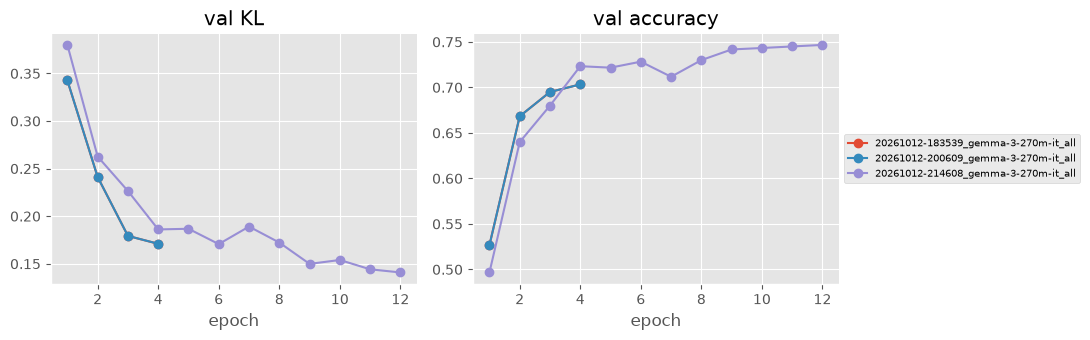

In [121]:
# training curves of all runs (validation KL per epoch)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for run_id in runs.index:
    h = pd.read_csv(f"{RUNS_DIR}/{run_id}/train_history.csv")
    ax[0].plot(h.epoch, h.val_kl, marker="o", label=run_id)
    ax[1].plot(h.epoch, h.val_acc, marker="o", label=run_id)
ax[0].set_title("val KL"); ax[1].set_title("val accuracy")
for a in ax: a.set_xlabel("epoch"); a.spines[["top", "right"]].set_visible(False)
ax[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

## Notes
* **Reading the score.** Gold is the average of three teacher samples; the dataset card puts teacher self-agreement at
  ~0.735 accuracy, so scores far above that mean the model is fitting teacher quirks.
* The leaderboard sends all five questions in one request; this notebook asks one question per forward pass
  (5 passes per case), which is the natural shape for a classifier-style fine-tune. Say so when submitting.
* 1,080 training cases are used (120 held out for epoch selection). Once hyperparameters are settled you can set
  `VAL_FRAC = 0` with a fixed `EPOCHS` to train on all 1,200 (the best-epoch logic then needs a val set, so keep
  the last epoch instead).
* To trade calibration for accuracy, select epochs on `val_acc` instead of `val_kl`.